# Ticket Trend Processing: From Weekly Records to Shared Curves

## Goal

Explain and reproduce how the **Shared trends** dashboard is calculated, one stage at a time.
This is a teaching companion to the existing individual-camera and clustering notebooks.
Every example below comes from the frozen project data; small examples illustrate arithmetic
and do not replace the full-cohort estimates.

**Reading route:** source receipts → weekly records → time alignment → missingness →
fixed cohorts → camera-specific baselines → cross-camera averages → smoothing →
uncertainty → calendar-time and sensitivity views → dashboard reconciliation.

**Scope:** issue dates January 1, 2016–August 30, 2026; the October 14, 2026 extraction;
4,610 original normalized-address/camera-type groups. Complete weekly coverage begins
July 4, 2016. All dates and original confidence labels are preserved.
The default 52-week cohort contains 3,124 speed groups and 46 red-light groups.

This notebook reruns the shared-trend calculations from the saved weekly aggregates.
It documents upstream ticket cleaning using saved receipts; it does **not** download or
deduplicate the raw tickets again. It neither overwrites the dashboard nor refits clusters.
A group is not necessarily one physical device. Counts are not exposure-adjusted rates
or estimates of a causal effect.

## Setup

Open this notebook anywhere inside the repository and select its pinned Python environment.
Run cells in order. The repository's uv.lock pins the environment; the original aggregate
files and analysis modules must be present to rerun. Saved outputs can be read without them.
Only new files under outputs/trend_walkthrough are written.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, inspect
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown, Code
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Run this notebook inside the project repository.")
    ROOT = ROOT.parent
DELIVERY = ROOT / "experiments/camera-ticket-trends"
INPUT = DELIVERY / "outputs"
SAVED = INPUT / "shared_trends"
OUT = INPUT / "trend_walkthrough"
OUT.mkdir(exist_ok=True)
sys.path[:0] = [str(ROOT), str(DELIVERY)]
from preprocessing.camera_shared_trends import (
    load_inputs, aligned_panels, eligibility_table, normalize_baseline, descriptive_rows,
)
from validation.camera_shared_trends import bootstrap_mean
from validation.camera_trend_walkthrough import (
    compare_trend_tables, verify_fixed_cohort_arithmetic,
)
from validation.camera_shared_trends import describe_matrix
from shared_presentation import finish, plot_sensitivities, plot_calendar, plot_cohorts

manifest = json.loads((SAVED / "analysis_manifest.json").read_text(encoding="utf-8"))
config = manifest["configuration"].copy()
HORIZON = config["primary_horizon"]
BASELINE = list(range(1, config["baseline_weeks"] + 1))
EXAMPLE_WEEK = 20
TYPES = ["Speed", "Red Light"]
COLORS = ["#2864a5", "#c46a25", "#60804c"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.max_colwidth", 55)
display(pd.DataFrame({
    "Setting": ["Input snapshot", "Issue-date cutoff", "Complete coverage starts",
                "Primary follow-up", "Baseline", "Bootstrap resamples", "Random seed", "Python"],
    "Value": [manifest["input_snapshot"], config["cutoff"], config["coverage_start"],
              f"{HORIZON} weeks", f"{len(BASELINE)} weeks", config["bootstrap_repeats"],
              config["seed"], platform.python_version()]
}))

,Setting,Value
0,Input snapshot,2026-10-14
1,Issue-date cutoff,2026-08-30
2,Complete coverage starts,2016-07-04
3,Primary follow-up,52 weeks
4,Baseline,13 weeks
5,Bootstrap resamples,500
6,Random seed,42
7,Python,3.13.16


## Steps

### 1. Verify the frozen inputs

The input hashes must match the snapshot used by the existing dashboard. This prevents
mixing updated tickets or camera definitions into an explanation of the earlier result.

In [2]:
input_checks = []
for filename, expected in manifest["inputs"].items():
    actual = hashlib.sha256((INPUT / filename).read_bytes()).hexdigest()
    assert actual == expected, f"Changed input: {filename}"
    input_checks.append({"File": filename, "SHA-256": actual, "Matches snapshot": True})
display(pd.DataFrame(input_checks))
summary, weekly, audit = load_inputs(INPUT)
saved_trends = pd.read_csv(SAVED / "shared_trends.csv")
saved_calendar = pd.read_csv(SAVED / "calendar_trends.csv")
saved_eligibility = pd.read_csv(SAVED / "camera_eligibility.csv")

,File,SHA-256,Matches snapshot
0,camera_summary.csv,1922873b06e09748006124a2b4b6f3f467f41920e3a1837cce5...,True
1,camera_weekly_trends.parquet,c462fb38133c193e672cb5b14f7ebb62dde403c37e9ccbb691c...,True
2,reconciliation.json,78303cbde46cf112630e88fe58e43a7ed4df2de233cc78b2b6b...,True
3,registry_pin.json,3d8d9b3e5c8bfd2497b8992db4dd9d0a1cb74f70c86c41c6d3a...,True


### 2. Understand the upstream ticket pipeline

Official FY2017–FY2027 files were filtered to violation codes **36 (speed)** and **7 (red light)**.
The query uses actual issue dates. Across fiscal-year files, duplicate summons numbers were
resolved in favor of the newer fiscal year, then the higher source row ID.
Eric's unchanged address-cleaning rules map tickets to one normalized address/type group.
Tickets before its unchanged inferred activation are excluded from the post-activation histories.

These counts are read from the original reconciliation receipt, not newly extracted here.
All 11 requested files finished downloading, but omitting FY2016 still leaves early-2016
coverage incomplete. Unmatched addresses are retained in the original audit.

In [3]:
lineage = pd.DataFrame([
    ("Downloaded source rows", audit["source_records"]),
    ("Duplicate rows removed", audit["duplicate_rows_removed"]),
    ("Unique summons numbers", audit["unique_identifiers"]),
    ("Unmatched unique tickets", audit["unmatched_records"]),
    ("Matched tickets, all selected dates", audit["matched_records_all_dates"]),
    ("Matched tickets before inferred activation", audit["tickets_before_activation"]),
    ("Matched tickets on/after inferred activation", audit["analysis_ticket_count"]),
    ("Weekly group records", len(weekly)),
    ("Original address/type groups", len(summary)),
], columns=["Stage / accounting item", "Records"])
display(lineage)
assert audit["source_records"] - audit["duplicate_rows_removed"] == audit["unique_identifiers"]
assert audit["matched_records_all_dates"] + audit["unmatched_records"] == audit["unique_identifiers"]
assert audit["matched_records_all_dates"] - audit["tickets_before_activation"] == audit["analysis_ticket_count"]
assert weekly.observed_ticket_count.sum() == audit["analysis_ticket_count"]
source_rows = [{"Fiscal year": s["fiscal_year"], "Dataset ID": s["dataset_id"],
                "Source": "https://data.cityofnewyork.us/d/" + s["dataset_id"],
                "Complete": s["complete"]} for s in audit["source_counts"]]
display(pd.DataFrame(source_rows))

,Stage / accounting item,Records
0,Downloaded source rows,45880884
1,Duplicate rows removed,1886216
2,Unique summons numbers,43994668
3,Unmatched unique tickets,1754648
4,"Matched tickets, all selected dates",42240020
5,Matched tickets before inferred activation,72457
6,Matched tickets on/after inferred activation,42167563
7,Weekly group records,849122
8,Original address/type groups,4610


,Fiscal year,Dataset ID,Source,Complete
0,2017,2bnn-yakx,https://data.cityofnewyork.us/d/2bnn-yakx,True
1,2018,a5td-mswe,https://data.cityofnewyork.us/d/a5td-mswe,True
2,2019,faiq-9dfq,https://data.cityofnewyork.us/d/faiq-9dfq,True
3,2020,p7t3-5i9s,https://data.cityofnewyork.us/d/p7t3-5i9s,True
4,2021,kvfd-bves,https://data.cityofnewyork.us/d/kvfd-bves,True
5,2022,7mxj-7a6y,https://data.cityofnewyork.us/d/7mxj-7a6y,True
6,2023,869v-vr48,https://data.cityofnewyork.us/d/869v-vr48,True
7,2024,8zf9-spf8,https://data.cityofnewyork.us/d/8zf9-spf8,True
8,2025,m5vz-tzqv,https://data.cityofnewyork.us/d/m5vz-tzqv,True
9,2026,9mwx-gamw,https://data.cityofnewyork.us/d/9mwx-gamw,True


### 3. Inspect the weekly counting unit

Each input row is **one address/type group × one Monday-starting calendar week**.
A unique ticket contributes once. Zero-ticket gaps inside a covered history remain zeros.
This notebook checks the key before any pivot, so duplicate weeks cannot be silently averaged.

- **observed_ticket_count:** actual matched tickets, including partial or uncovered weeks.
- **source_complete:** whether the underlying source coverage is complete.
- **is_complete_week:** whether source coverage is complete and the entire Monday–Sunday week
  falls inside inferred activation through the last actual ticket.
- **ticket_count:** coverage-aware value for the original individual-camera chart.

The shared-trend primary panel uses only is_complete_week observations. Its stricter
full-week rule differs from simply using every non-null ticket_count in the individual view.

In [4]:
assert summary.camera_id.is_unique
assert not weekly.duplicated(["camera_id", "week_start"]).any()
display(summary[["camera_id", "search_query", "camera_type",
                 "inferred_activation_date", "last_actual_ticket_date"]].head(5))
weekly_columns = ["camera_id", "week_start", "observed_ticket_count",
                  "source_complete", "is_complete_week", "is_partial_week", "ticket_count"]
display(weekly[weekly_columns].head(8))
display(pd.DataFrame([
    {"Field": "observed_ticket_count", "Meaning": "Unique tickets actually observed"},
    {"Field": "primary panel = 0", "Meaning": "Complete eligible week with no observed tickets"},
    {"Field": "primary panel = NaN", "Meaning": "Incomplete, uncovered, or outside the observed history"},
]))

,camera_id,search_query,camera_type,inferred_activation_date,last_actual_ticket_date
0,cam_252f148e5cf5b50a,"1 AV E 7ST. - E 1 4 ST, NEW YORK, NY",Speed,2016-06-20,2022-07-19
1,cam_01020d7dded2808f,"1 AV E102 ST. - E 110 ST, NEW YORK, NY",Speed,2016-06-13,2026-03-18
2,cam_6c1d3bfa071503e0,"1 AV E117 ST. - E 124 ST, NEW YORK, NY",Speed,2016-09-12,2025-10-16
3,cam_e7978d32ac633246,"1 AV E92 ST. - E1 00 ST, NEW YORK, NY",Speed,2017-01-09,2026-04-09
4,cam_834087bed0f73bb8,"1 AV. E 3 ST - E 4 ST, NEW YORK, NY",Speed,2021-11-15,2023-12-28


,camera_id,week_start,observed_ticket_count,source_complete,is_complete_week,is_partial_week,ticket_count
0,cam_252f148e5cf5b50a,2016-06-20,3,False,False,False,NaN
1,cam_252f148e5cf5b50a,2016-06-27,0,False,False,False,NaN
2,cam_252f148e5cf5b50a,2016-07-04,0,True,True,False,0.0
3,cam_252f148e5cf5b50a,2016-07-11,0,True,True,False,0.0
4,cam_252f148e5cf5b50a,2016-07-18,0,True,True,False,0.0
5,cam_252f148e5cf5b50a,2016-07-25,0,True,True,False,0.0
6,cam_252f148e5cf5b50a,2016-08-01,0,True,True,False,0.0
7,cam_252f148e5cf5b50a,2016-08-08,0,True,True,False,0.0


,Field,Meaning
0,observed_ticket_count,Unique tickets actually observed
1,primary panel = 0,Complete eligible week with no observed tickets
2,primary panel = NaN,"Incomplete, uncovered, or outside the observed history"


### 4. Align time without moving missing early observations

For group $i$, let $a_i$ be the first Monday on or after inferred activation.
A calendar-week start $d$ becomes:

$$
t = 1 + (d-a_i)/7\text{ days}.
$$

A partial week before $a_i$ is not Week 1. If Week 1 is missing, it stays missing;
the next available week is not relabeled. The existing function returns three panels:
primary relative time, a fixed-cutoff sensitivity, and calendar time.

In [5]:
meta, primary, administrative, calendar = aligned_panels(summary, weekly, audit, config)
eligibility = eligibility_table(meta, primary, administrative, config)
matrices = {
    kind: primary.loc[meta.index[meta.camera_type.eq(kind)], 1:HORIZON].dropna()
    for kind in TYPES
}
# Deterministic teaching examples near the 10th, 50th, and 90th volume percentiles.
examples = []
for kind, matrix in matrices.items():
    ordered = matrix.mean(axis=1).sort_values(kind="stable")
    for label, q in [("Low volume", .1), ("Middle volume", .5), ("High volume", .9)]:
        camera_id = ordered.index[round(q * (len(ordered) - 1))]
        examples.append({"camera_id": camera_id, "Example": kind + " / " + label,
                         "camera_type": kind, "Weekly mean": ordered.loc[camera_id]})
examples = pd.DataFrame(examples).set_index("camera_id", drop=False)
display(examples.join(meta[["search_query", "inferred_activation_date", "anchor"]]).round(2))
example_id = examples.index[1]
trace = weekly.loc[weekly.camera_id.eq(example_id), weekly_columns].sort_values("week_start").head(8).copy()
trace["anchor"] = meta.loc[example_id, "anchor"]
trace["relative_week"] = ((pd.to_datetime(trace.week_start) - trace.anchor).dt.days // 7) + 1
display(trace.drop(columns=["camera_id", "ticket_count"]))

C:\Users\4060ti\AppData\Local\Temp\ipykernel_52824\132356735.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(examples.join(meta[["search_query", "inferred_activation_date", "anchor"]]).round(2))


,camera_id,Example,camera_type,Weekly mean,search_query,inferred_activation_date,anchor
camera_id,,,,,,,
cam_94204bf2b2c1c84f,cam_94204bf2b2c1c84f,Speed / Low volume,Speed,0.31,"4 AV 17 ST - 24 S T, NEW YORK, NY",2017-01-09,2017-01-09
cam_65555378567c6155,cam_65555378567c6155,Speed / Middle volume,Speed,15.00,"WARING AVE AND DEME YER ST, NEW YORK, NY",2024-04-29,2024-04-29
cam_fa83087ecaece492,cam_fa83087ecaece492,Speed / High volume,Speed,154.77,"BLOOMINGDALE RD AND SARCONA CT, NEW YORK, NY",2019-12-30,2019-12-30
cam_e28346fcf1c22eaf,cam_e28346fcf1c22eaf,Red Light / Low volume,Red Light,6.10,"PARK AVE AND WAS HINGTON AVE, NEW YORK, NY",2016-11-21,2016-11-21
cam_0676c16262accdcd,cam_0676c16262accdcd,Red Light / Middle volume,Red Light,41.65,"COLLEGE POINT BLV D AND ROOSEVELT AVE, NEW YORK, NY",2025-07-28,2025-07-28
cam_7910ad2030a7d2ca,cam_7910ad2030a7d2ca,Red Light / High volume,Red Light,104.90,"NARROWS RD S AND HYLAN BLVD, NEW YORK, NY",2021-11-29,2021-11-29


,week_start,observed_ticket_count,source_complete,is_complete_week,is_partial_week,anchor,relative_week
808323,2024-04-29,47,True,True,False,2024-04-29,1
808324,2024-05-06,61,True,True,False,2024-04-29,2
808325,2024-05-13,52,True,True,False,2024-04-29,3
808326,2024-05-20,48,True,True,False,2024-04-29,4
808327,2024-05-27,31,True,True,False,2024-04-29,5
808328,2024-06-03,44,True,True,False,2024-04-29,6
808329,2024-06-10,32,True,True,False,2024-04-29,7
808330,2024-06-17,33,True,True,False,2024-04-29,8


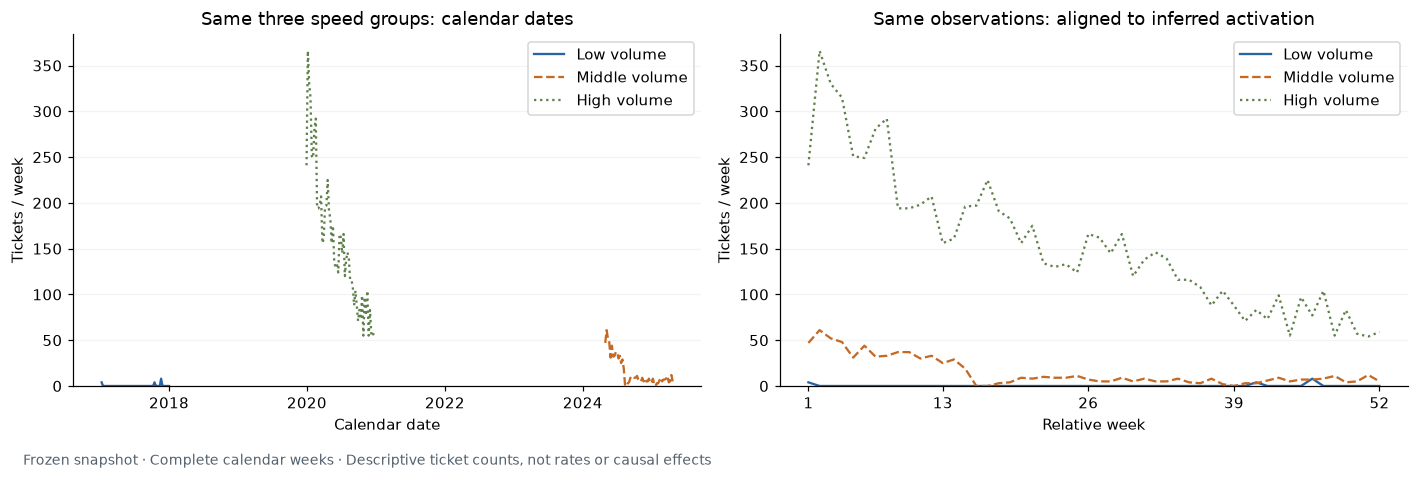

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for color, style, camera_id in zip(COLORS, ["-", "--", ":"], examples.index[:3]):
    values = matrices["Speed"].loc[camera_id]
    dates = meta.loc[camera_id, "anchor"] + pd.to_timedelta((values.index - 1) * 7, unit="D")
    label = examples.loc[camera_id, "Example"].replace("Speed / ", "")
    axes[0].plot(dates, values, color=color, ls=style, label=label)
    axes[1].plot(values.index, values, color=color, ls=style, label=label)
axes[0].set_title("Same three speed groups: calendar dates")
axes[0].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=6))
axes[0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[0].xaxis.get_major_locator()))
axes[0].set_xlabel("Calendar date")
axes[1].set_title("Same observations: aligned to inferred activation")
axes[1].set_xlabel("Relative week")
axes[1].set_xticks([1, 13, 26, 39, 52])
for ax in axes:
    ax.set_ylabel("Tickets / week"); ax.set_ylim(bottom=0)
    ax.legend(); ax.grid(axis="y", alpha=.15)
finish(fig, OUT, "01_time_alignment")

### 5. Keep missing weeks separate from observed zeros

The primary panel has one row per original group and one column per relative week.
Only complete weeks supply values. A group can have actual tickets in a partial week
while its primary-panel value is missing. The fixed-cutoff sensitivity instead asks
how many tickets were observed in covered weeks through August 30, 2026, including
zero after the last ticket; this does not establish continued equipment operation.

In [7]:
selected_window = primary.loc[:, 1:HORIZON]
display(pd.DataFrame([{
    "Type": kind, "Original groups": int(meta.camera_type.eq(kind).sum()),
    "Complete camera-weeks": int(selected_window.loc[meta.camera_type.eq(kind)].notna().sum().sum()),
    "Observed zero camera-weeks": int(selected_window.loc[meta.camera_type.eq(kind)].eq(0).sum().sum()),
    "Missing camera-weeks": int(selected_window.loc[meta.camera_type.eq(kind)].isna().sum().sum())
} for kind in TYPES]))
cases = []
for label, mask in [
    ("Observed zero in a complete week", weekly.is_complete_week & weekly.observed_ticket_count.eq(0)),
    ("Observed tickets in an incomplete week", ~weekly.is_complete_week & weekly.observed_ticket_count.gt(0)),
    ("Incomplete source coverage", ~weekly.source_complete),
]:
    found = weekly.loc[mask, weekly_columns].head(1).copy()
    found.insert(0, "Case", label)
    cases.append(found)
display(pd.concat(cases, ignore_index=True).drop(columns="ticket_count"))

,Type,Original groups,Complete camera-weeks,Observed zero camera-weeks,Missing camera-weeks
0,Speed,3993,179130,47627,28506
1,Red Light,617,18864,1046,13220


,Case,camera_id,week_start,observed_ticket_count,source_complete,is_complete_week,is_partial_week
0,Observed zero in a complete week,cam_252f148e5cf5b50a,2016-07-04,0,True,True,False
1,Observed tickets in an incomplete week,cam_252f148e5cf5b50a,2016-06-20,3,False,False,False
2,Incomplete source coverage,cam_252f148e5cf5b50a,2016-06-20,3,False,False,False


### 6. Select the fixed cohort

A 52-week member must have all 52 anchored weeks complete. It is not enough to have
any 52 complete weeks later in the history. Zero-ticket weeks are valid; missing weeks
are not. The same selected groups contribute throughout this primary window.

Requiring a history through the last ticket selects longer histories and uses information
observed after activation. The eligible cohort is therefore not a random sample of devices.

In [8]:
coverage = eligibility.groupby("camera_type").agg(
    original_groups=("camera_id", "size"), eligible_26=("eligible_26w", "sum"),
    eligible_52=("eligible_52w", "sum"), eligible_104=("eligible_104w", "sum"),
    fixed_cutoff_52=("eligible_administrative_52w", "sum"))
display(coverage)
display(saved_eligibility.groupby(["camera_type", "exclusion_reason"]).size().rename("Groups").reset_index())
display(pd.DataFrame([{"Type": kind, "Matrix rows": matrix.shape[0],
                       "Matrix columns": matrix.shape[1], "Missing cells": int(matrix.isna().sum().sum())}
                      for kind, matrix in matrices.items()]))
# Rows are cameras; columns are relative weeks. This preview is not the analysis sample.
display(matrices["Speed"].loc[examples.index[:3], [1, 2, 3, 13, 20, 26, 52]])

,original_groups,eligible_26,eligible_52,eligible_104,fixed_cutoff_52
camera_type,,,,,
Red Light,617,222,46,42,89
Speed,3993,3287,3124,2567,3690


,camera_type,exclusion_reason,Groups
0,Red Light,Administrative cutoff before 52 complete weeks,371
1,Red Light,Eligible,46
2,Red Light,Incomplete coverage at inferred activation,157
3,Red Light,Last ticket before end of 52-week window or incompl...,43
4,Speed,Administrative cutoff before 52 complete weeks,134
5,Speed,Eligible,3124
6,Speed,Incomplete coverage at inferred activation,169
7,Speed,Last ticket before end of 52-week window or incompl...,566


,Type,Matrix rows,Matrix columns,Missing cells
0,Speed,3124,52,0
1,Red Light,46,52,0


relative_week,1,2,3,13,20,26,52
camera_id,,,,,,,
cam_94204bf2b2c1c84f,4.0,0.0,0.0,0.0,0.0,0.0,0.0
cam_65555378567c6155,47.0,61.0,52.0,25.0,9.0,7.0,5.0
cam_fa83087ecaece492,241.0,366.0,330.0,156.0,156.0,166.0,59.0


### 7. Calculate each group's baseline and normalized index

$$
b_i = \frac{1}{13}\sum_{t=1}^{13}y_{i,t},
\qquad I_{i,t}=100\,\frac{y_{i,t}}{b_i}.
$$

The baseline is a **13-week average**, not the first week's count. A first-week index
above 100 is normal. Missing or zero baselines produce missing indices, never infinite
values or artificial zeros. Original counts remain available.
The exact production normalization function is shown below.

In [9]:
display(Code(inspect.getsource(normalize_baseline), language="python"))
indexed = {kind: normalize_baseline(matrix, BASELINE) for kind, matrix in matrices.items()}
baseline_trace = []
for camera_id, example in examples.iterrows():
    matrix, indices = matrices[example.camera_type], indexed[example.camera_type]
    baseline_sum = matrix.loc[camera_id, BASELINE].sum()
    baseline_trace.append({"Example": example.Example, "camera_id": camera_id,
        "First 13-week sum": baseline_sum, "Baseline = sum / 13": baseline_sum / 13,
        f"Week {EXAMPLE_WEEK} count": matrix.loc[camera_id, EXAMPLE_WEEK],
        f"Week {EXAMPLE_WEEK} index": indices.loc[camera_id, EXAMPLE_WEEK],
        "Mean index in baseline weeks": indices.loc[camera_id, BASELINE].mean()})
baseline_trace = pd.DataFrame(baseline_trace)
display(baseline_trace.drop(columns="camera_id").round(3))
baseline_trace.to_csv(OUT / "example_baseline_arithmetic.csv", index=False)

def normalize_baseline(matrix, baseline_columns):
    baseline = matrix.loc[:, baseline_columns]
    means = baseline.mean(axis=1).where(baseline.notna().all(axis=1) & baseline.mean(axis=1).gt(0))
    return matrix.div(means, axis=0) * 100

,Example,First 13-week sum,Baseline = sum / 13,Week 20 count,Week 20 index,Mean index in baseline weeks
0,Speed / Low volume,4.0,0.308,0.0,0.000,100.0
1,Speed / Middle volume,510.0,39.231,9.0,22.941,100.0
2,Speed / High volume,3274.0,251.846,156.0,61.943,100.0
3,Red Light / Low volume,88.0,6.769,1.0,14.773,100.0
4,Red Light / Middle volume,395.0,30.385,0.0,0.000,100.0
5,Red Light / High volume,1371.0,105.462,98.0,92.925,100.0


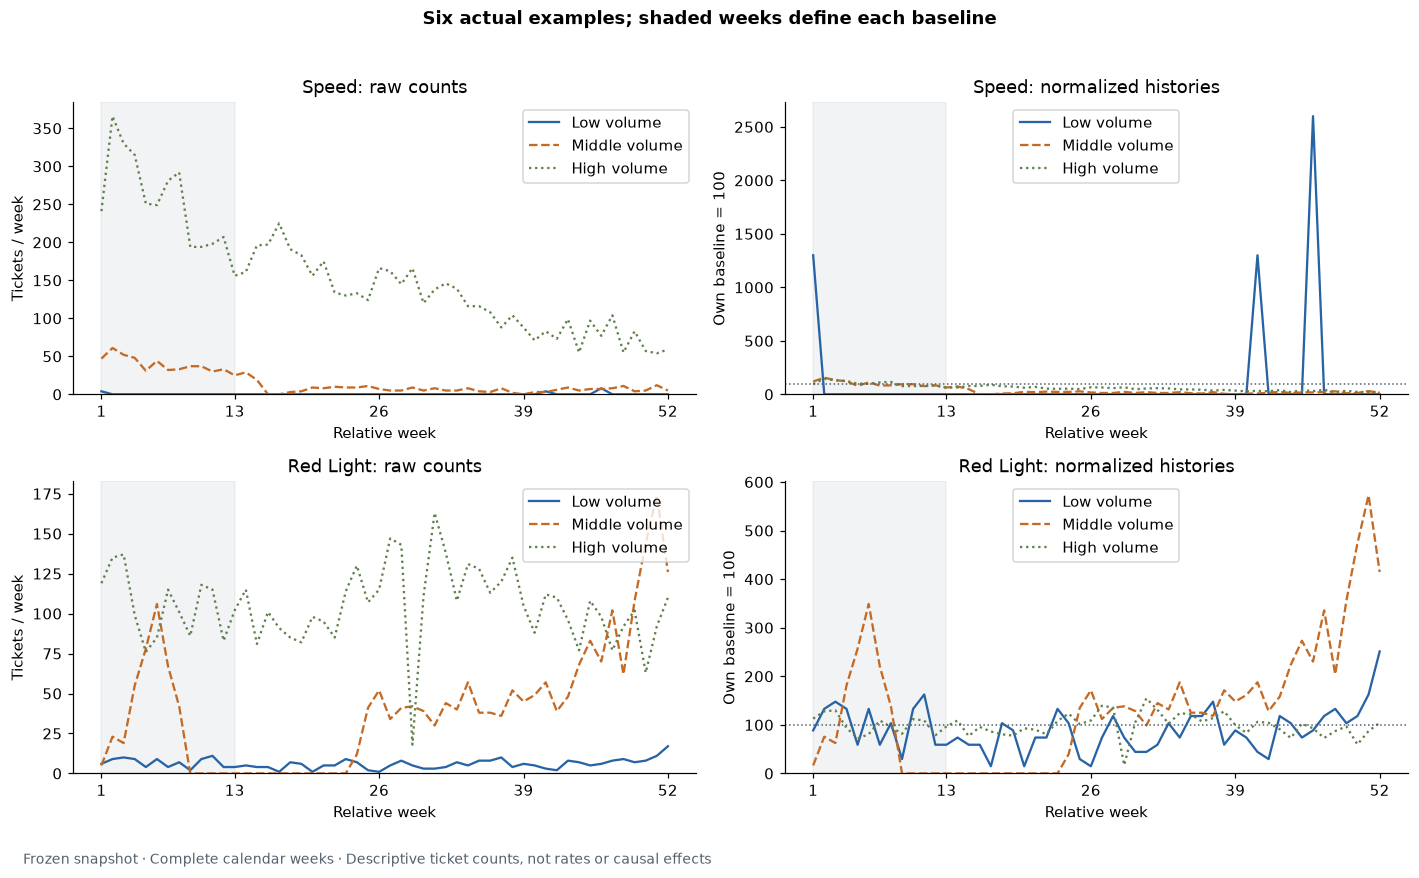

The low-volume speed example has a baseline of only **0.308 tickets/week**. Its largest index is **2,600**, so it expands the vertical scale. This is denominator amplification, not thousands of actual tickets. The baseline-at-least-five sensitivity addresses this issue.

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, kind in enumerate(TYPES):
    ids = examples.index[examples.camera_type.eq(kind)]
    for color, style, camera_id in zip(COLORS, ["-", "--", ":"], ids):
        label = examples.loc[camera_id, "Example"].split(" / ")[1]
        axes[row, 0].plot(range(1, 53), matrices[kind].loc[camera_id], color=color, ls=style, label=label)
        axes[row, 1].plot(range(1, 53), indexed[kind].loc[camera_id], color=color, ls=style, label=label)
    for column, unit in enumerate(["Tickets / week", "Own baseline = 100"]):
        ax = axes[row, column]
        ax.set_title(f"{kind}: {'raw counts' if column == 0 else 'normalized histories'}")
        ax.set_ylabel(unit); ax.set_xlabel("Relative week")
        ax.axvspan(1, 13, color="#bcc4cc", alpha=.2)
        ax.set_xticks([1, 13, 26, 39, 52]); ax.set_ylim(bottom=0); ax.legend()
    axes[row, 1].axhline(100, color="#53616d", ls=":", lw=1)
fig.suptitle("Six actual examples; shaded weeks define each baseline", weight="bold")
finish(fig, OUT, "02_baseline_normalization")
low_id = examples.index[0]
low_baseline = matrices["Speed"].loc[low_id, BASELINE].mean()
display(Markdown(
    f"The low-volume speed example has a baseline of only **{low_baseline:.3f} tickets/week**. "
    f"Its largest index is **{indexed['Speed'].loc[low_id].max():,.0f}**, "
    "so it expands the vertical scale. This is denominator amplification, not thousands "
    "of actual tickets. The baseline-at-least-five sensitivity addresses this issue."))

### 8. Average across groups, not across all tickets

At relative week $t$, the two displayed means are:
$$
\bar y_t=\frac{\sum_i y_{i,t}}{N_t},
\qquad \bar I_t=\frac{\sum_{i:b_i>0} I_{i,t}}{N^{index}_t}.
$$

Each group has equal weight. High-volume groups can still dominate the raw-count mean.
Normalizing each group first makes the second mean an average of relative levels.
It is **not** the pooled count divided by a pooled baseline.
The production descriptive function also calculates median and quartiles.

In [11]:
raw_stats = {kind: descriptive_rows(matrix) for kind, matrix in matrices.items()}
index_stats = {kind: descriptive_rows(matrix) for kind, matrix in indexed.items()}
arithmetic = []
for kind in TYPES:
    values = matrices[kind][EXAMPLE_WEEK]
    indices = indexed[kind][EXAMPLE_WEEK].dropna()
    baselines = matrices[kind][BASELINE].mean(axis=1)
    arithmetic.append({
        "Type": kind, "Relative week": EXAMPLE_WEEK,
        "Raw numerator: sum of counts": values.sum(), "Raw denominator: groups": values.count(),
        "Raw mean": values.sum() / values.count(),
        "Index numerator: sum of individual indices": indices.sum(),
        "Index denominator: groups": indices.count(),
        "Mean individual index": indices.sum() / indices.count(),
        "Different quantity: pooled ratio index": 100 * values.sum() / baselines.sum(),
    })
display(pd.DataFrame(arithmetic).set_index("Type").T.round(4))
display(raw_stats["Speed"].set_index("time").loc[[1, 13, 20, 26, 52]].round(3))

Type,Speed,Red Light
Relative week,20.0000,20.0000
Raw numerator: sum of counts,177441.0000,2095.0000
Raw denominator: groups,3124.0000,46.0000
Raw mean,56.7993,45.5435
Index numerator: sum of individual indices,242980.3355,3757.1784
Index denominator: groups,3124.0000,46.0000
Mean individual index,77.7786,81.6778
Different quantity: pooled ratio index,67.2941,81.3398


,n,mean,median,q25,q75
time,,,,,
1,3124,69.177,17.0,6.0,50.25
13,3124,66.623,15.0,1.0,62.00
20,3124,56.799,13.0,1.0,54.00
26,3124,54.625,12.0,1.0,50.00
52,3124,49.056,9.0,0.0,38.00


### 9. Smooth the shared curve

The four-week line is a trailing average of the current cross-group mean and its
previous three weekly means. It requires four consecutive nonmissing values.
Weeks 1–3 therefore have no four-week result. Smoothing does not alter the underlying
weekly observations or turn missing values into zero.

,time,mean,trailing_four_week_mean
0,1,239.5301,NaN
1,2,125.3685,NaN
2,3,119.4357,NaN
3,4,98.6865,145.7552
4,5,89.4331,108.2309
5,6,87.8209,98.8440
6,7,84.9804,90.2302
7,8,81.4865,85.9302


**Numerical check for Week 4 (Speed):** (239.5301, 125.3685, 119.4357, 98.6865) / 4 = **145.7552**.

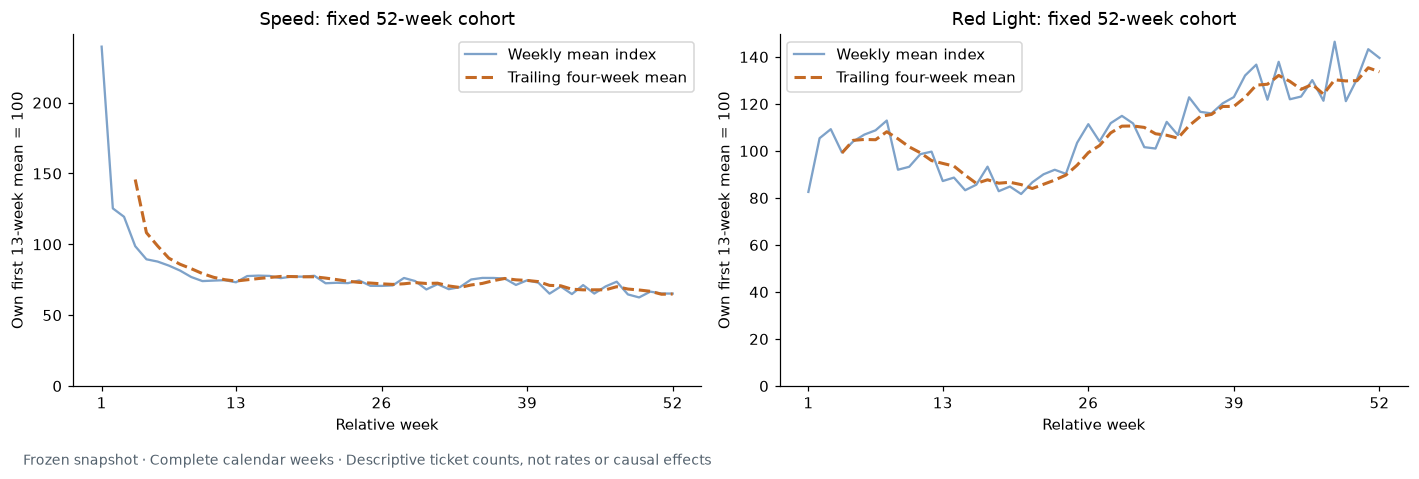

In [12]:
smoothing = index_stats["Speed"][["time", "mean"]].copy()
smoothing["trailing_four_week_mean"] = smoothing["mean"].rolling(4, min_periods=4).mean()
display(smoothing.head(8).round(4))
display(Markdown(
    f"**Numerical check for Week 4 (Speed):** "
    f"({', '.join(f'{x:.4f}' for x in smoothing['mean'].iloc[:4])}) / 4 "
    f"= **{smoothing.trailing_four_week_mean.iloc[3]:.4f}**."))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, kind in zip(axes, TYPES):
    frame = index_stats[kind]
    ax.plot(frame.time, frame["mean"], color=COLORS[0], alpha=.6, label="Weekly mean index")
    ax.plot(frame.time, frame["mean"].rolling(4, min_periods=4).mean(),
            color=COLORS[1], ls="--", lw=2, label="Trailing four-week mean")
    ax.set_title(f"{kind}: fixed 52-week cohort")
    ax.set_xlabel("Relative week"); ax.set_ylabel("Own first 13-week mean = 100")
    ax.set_xticks([1, 13, 26, 39, 52]); ax.set_ylim(bottom=0); ax.legend()
finish(fig, OUT, "03_smoothing")

### 10. Estimate uncertainty by resampling whole histories

The bootstrap draws groups with replacement, keeping all weeks of a chosen history
together. Each draw recalculates the mean at every week. The 2.5th and 97.5th percentiles
of 500 draws form a **pointwise 95% interval**. Seed 42 makes it reproducible.

The implementation uses multinomial multiplicities: selecting a group twice gives its
entire history weight 2 in that resample. It does not resample individual weeks independently.
These intervals quantify sensitivity to the sampled groups; spatial and shared-calendar
dependence are not modeled. They are not simultaneous bands or causal-effect intervals.

We now call the same assembly function as the dashboard, which combines all steps above.

In [13]:
display(Code(inspect.getsource(bootstrap_mean), language="python"))
rebuilt = {}
with threadpool_limits(limits=2):
    for kind in TYPES:
        rebuilt[kind] = describe_matrix(matrices[kind], indexed[kind], kind, "balanced_52", config)
reconstructed = pd.concat(rebuilt.values(), ignore_index=True).rename(columns={"time": "week"})
display(reconstructed[["camera_type", "week", "n", "index_n", "index_mean",
                        "index_ci_low", "index_ci_high"]].query("week in [1, 13, 26, 52]").round(3))

def bootstrap_mean(matrix, repeats=500, seed=42):
    """Pointwise percentile bounds resampling whole histories, not individual weeks."""
    values = np.asarray(matrix, dtype=float)
    values = values[~np.isnan(values).all(axis=1)]
    if len(values) < 2:
        return np.full((2, values.shape[1]), np.nan)
    rng = np.random.default_rng(seed)
    weights = rng.multinomial(len(values), np.full(len(values), 1 / len(values)), size=repeats).astype(float)
    denominators = weights @ np.isfinite(values)
    totals = weights @ np.nan_to_num(values)
    samples = np.divide(totals, denominators, out=np.full_like(totals, np.nan), where=denominators > 0)
    output = np.full((2, values.shape[1]), np.nan)
    valid = np.isfinite(values).sum(axis=0) >= 2
    output[:, valid] = np.nanpercentile(samples[:, valid], [2.5, 97.5], axis=0)
    return output

,camera_type,week,n,index_n,index_mean,index_ci_low,index_ci_high
0,Speed,1,3124,3124,239.530,228.704,251.856
12,Speed,13,3124,3124,73.196,70.666,76.045
25,Speed,26,3124,3124,70.648,66.174,75.579
51,Speed,52,3124,3124,65.230,60.346,71.071
52,Red Light,1,46,46,82.565,70.414,96.754
64,Red Light,13,46,46,87.189,74.266,100.992
77,Red Light,26,46,46,111.387,78.369,164.272
103,Red Light,52,46,46,139.564,101.234,187.062


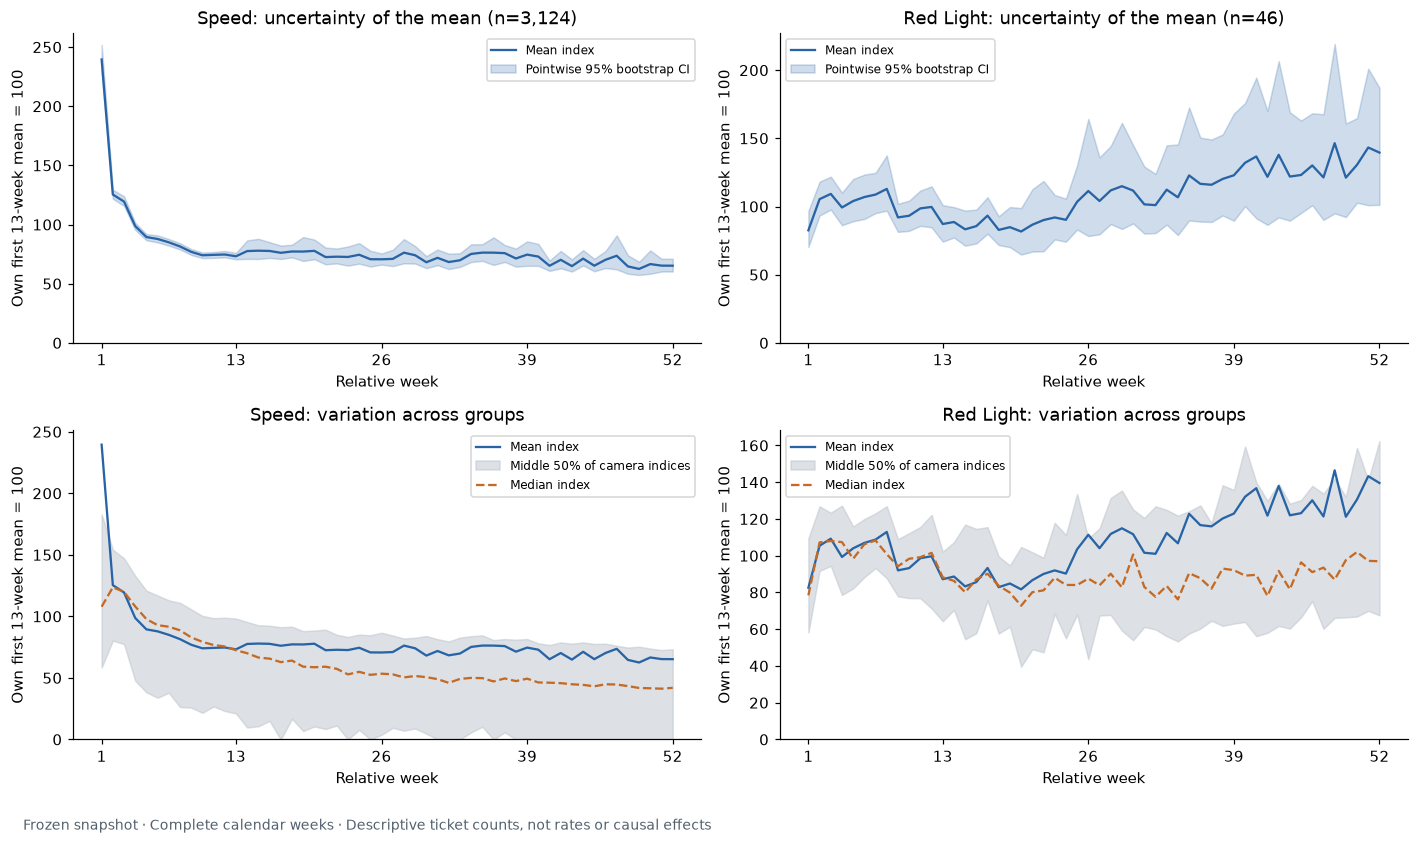

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for column, kind in enumerate(TYPES):
    frame = rebuilt[kind]
    for row in range(2):
        ax = axes[row, column]
        ax.plot(frame.time, frame.index_mean, color=COLORS[0], label="Mean index")
        if row == 0:
            ax.fill_between(frame.time, frame.index_ci_low, frame.index_ci_high,
                            color=COLORS[0], alpha=.22, label="Pointwise 95% bootstrap CI")
            ax.set_title(f"{kind}: uncertainty of the mean (n={len(matrices[kind]):,})")
        else:
            ax.fill_between(frame.time, frame.index_q25, frame.index_q75,
                            color="#bcc4cc", alpha=.5, label="Middle 50% of camera indices")
            ax.plot(frame.time, frame.index_median, color=COLORS[1], ls="--", label="Median index")
            ax.set_title(f"{kind}: variation across groups")
        ax.set_xlabel("Relative week"); ax.set_ylabel("Own first 13-week mean = 100")
        ax.set_xticks([1, 13, 26, 39, 52]); ax.set_ylim(bottom=0)
        ax.legend(fontsize=8)
finish(fig, OUT, "04_uncertainty_and_variation")

The upper panels show uncertainty in an average; the lower panels show differences
among individual histories. A narrow interval for the mean can coexist with substantial
variation across locations. Neither display says that 95% of individual cameras follow the mean.

### 11. Read the raw-count and indexed results together

The primary comparison uses weeks 1–13 versus weeks 40–52. The percentage change of
raw cohort means differs from the mean of individual relative changes.
The following values are calculated during this notebook run.

,Type,Groups,First 13-week mean tickets,Last 13-week mean tickets,Change of raw means (%),Last 13-week mean individual index
0,Speed,3124,84.40,52.41,-37.91,67.52
1,Red Light,46,55.99,61.14,9.19,131.25


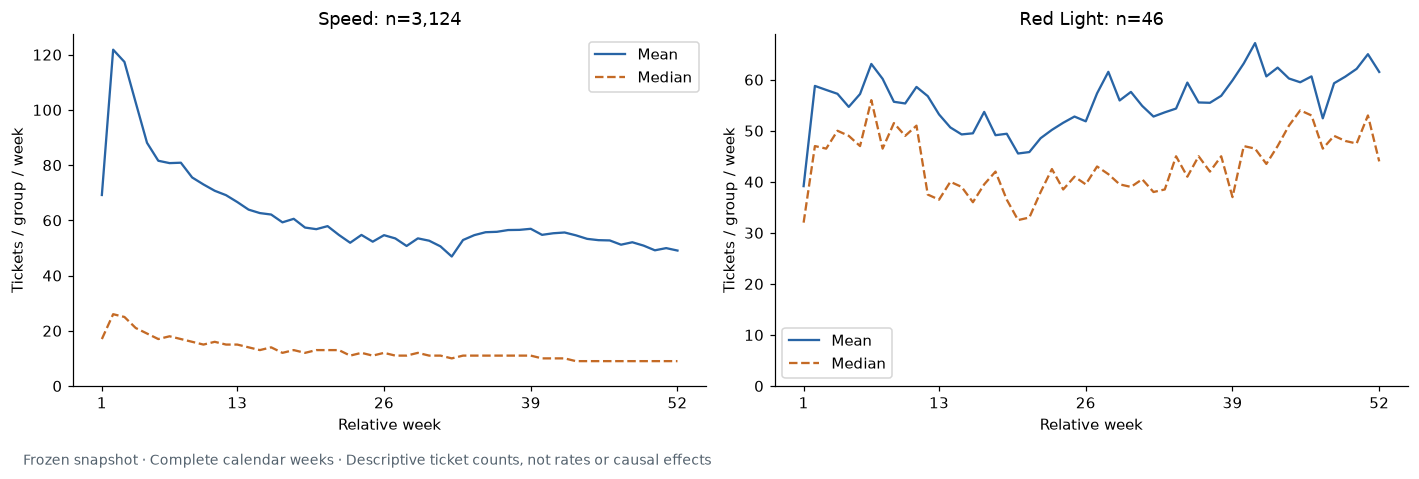

In [15]:
comparison = []
for kind, frame in rebuilt.items():
    early = frame.loc[frame.time.le(13), "raw_mean"].mean()
    late = frame.loc[frame.time.ge(40), "raw_mean"].mean()
    comparison.append({"Type": kind, "Groups": len(matrices[kind]),
        "First 13-week mean tickets": early, "Last 13-week mean tickets": late,
        "Change of raw means (%)": 100 * (late / early - 1),
        "Last 13-week mean individual index": frame.loc[frame.time.ge(40), "index_mean"].mean()})
comparison = pd.DataFrame(comparison)
display(comparison.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, kind in zip(axes, TYPES):
    frame = rebuilt[kind]
    ax.plot(frame.time, frame.raw_mean, color=COLORS[0], label="Mean")
    ax.plot(frame.time, frame.raw_median, color=COLORS[1], ls="--", label="Median")
    ax.set_title(f"{kind}: n={len(matrices[kind]):,}")
    ax.set_xlabel("Relative week"); ax.set_ylabel("Tickets / group / week")
    ax.set_xticks([1, 13, 26, 39, 52]); ax.set_ylim(bottom=0); ax.legend()
finish(fig, OUT, "05_actual_ticket_means")

### 12. Separate relative time from calendar time

Calendar-time averages align by the actual Monday date, so the set of eligible contributors
changes across dates. The denominator is recomputed each week. The lower panels show
that changing denominator. The index still uses each group's own first 13-week baseline,
not the first 13 dates in this calendar chart.

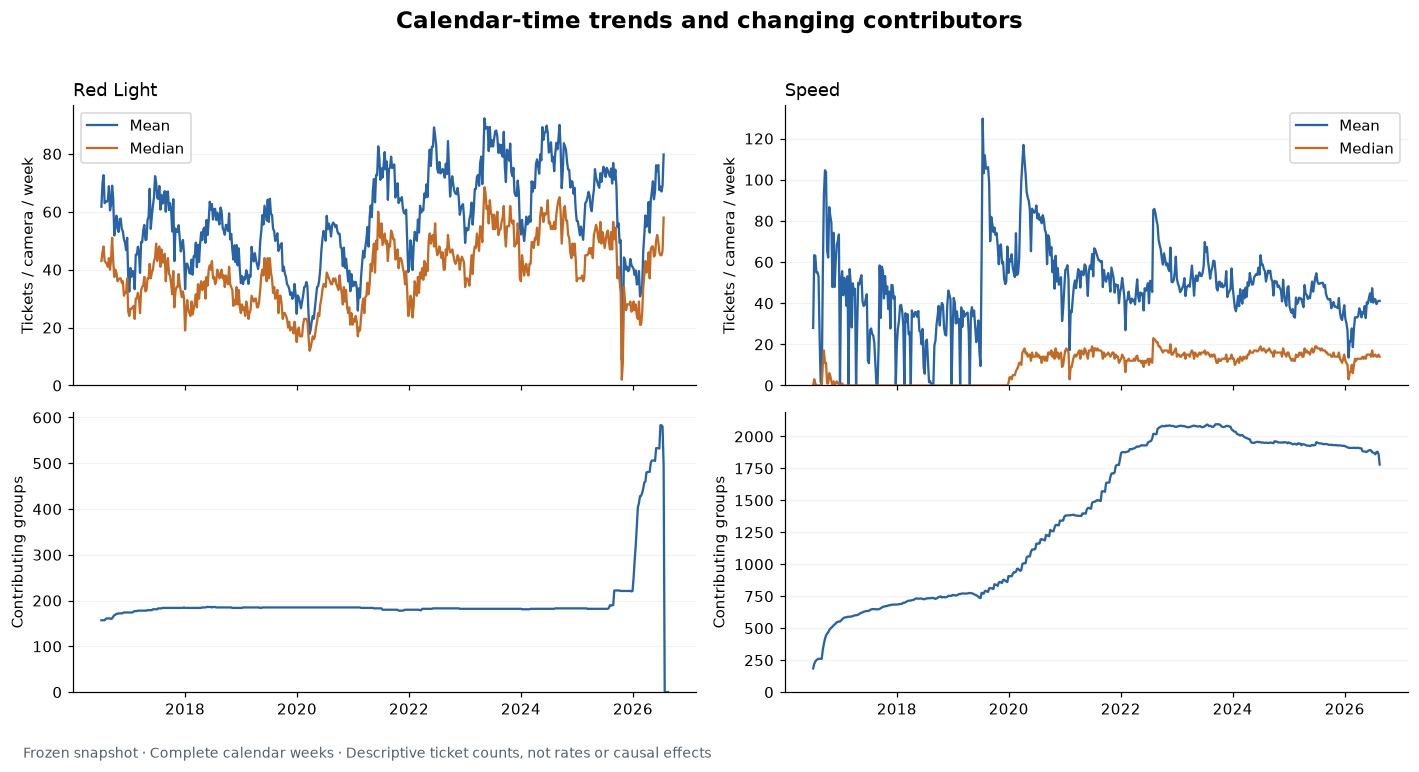

In [16]:
calendar_rebuilt = []
with threadpool_limits(limits=2):
    for kind in TYPES:
        ids = meta.index[meta.camera_type.eq(kind)]
        matrix = calendar.loc[ids]
        base = eligibility.loc[ids, "baseline_mean"].where(eligibility.loc[ids, "baseline_mean"].gt(0))
        calendar_rebuilt.append(describe_matrix(matrix, matrix.div(base, axis=0) * 100, kind, "calendar", config))
calendar_rebuilt = pd.concat(calendar_rebuilt, ignore_index=True).rename(columns={"time": "week_start"})
plot_calendar({"calendar_trends": calendar_rebuilt}, OUT)

### 13. Understand the alternative cohorts

These saved comparisons were generated by the original analysis and are reused here.
The primary and calendar curves above were recalculated in this notebook; the alternative
cohort curves below are not a new extraction or model fit.

| View | What changes | Interpretation |
|---|---|---|
| Fixed 26 / 52 / 104 weeks | Required uninterrupted complete window | Longer windows select older, longer histories |
| All available histories | Available groups change by relative week | Inspect the contributing-group count |
| High sustained confidence | Keep only Eric's original high label | Confidence refers to inferred activation |
| Fixed cutoff | Extend covered weeks to the administrative cutoff | Later zero means no observed ticket, not confirmed operation |
| Omit weeks 1–4 | Use weeks 5–52 and a weeks 5–17 baseline | Changes both the plotted window and normalization baseline |
| Baseline at least five | Remove very low positive baseline groups | Reduces amplification from small denominators |
| Inferred activation year | A separate fixed cohort for each year | Geography, policy, and traffic can differ between cohorts |

Activation was inferred from ticket activity, so early peaks and subsequent declines can
partly reflect the identification rule. These comparisons probe that sensitivity;
they do not remove it or establish a treatment effect.

first_raw_contributors  \
camera_type scenario_label                                                 
Red Light   Fixed cohort: 26 weeks                                   222   
            Fixed cohort: 52 weeks                                    46   
            Fixed cohort: 104 weeks                                   42   
            All available histories                                  457   
            High sustained confidence: 52 weeks                       45   
            Fixed 52-week cohort: omit weeks 1–4                      46   
            Fixed cutoff: 52 weeks                                    89   
            Baseline ≥5 tickets/week: 52 weeks                        43   
Speed       Fixed cohort: 26 weeks                                  3287   
            Fixed cohort: 52 weeks                                  3124   
            Fixed cohort: 104 weeks                                 2567   
            All available histories                                 3592   
            High sustained confidence: 52 weeks                     2396   
            Fixed 52-week cohort: omit weeks 1–4                    3124   
            Fixed cutoff: 52 weeks                                  3690   
            Baseline ≥5 tickets/week: 52 weeks                      2329   

                                                  last_raw_contributors  \
camera_type scenario_label                                                
Red Light   Fixed cohort: 26 weeks                                  222   
            Fixed cohort: 52 weeks                                   46   
            Fixed cohort: 104 weeks                                  42   
            All available histories                                  17   
            High sustained confidence: 52 weeks                      45   
            Fixed 52-week cohort: omit weeks 1–4                     46   
            Fixed cutoff: 52 weeks                                   89   
            Baseline ≥5 tickets/week: 52 weeks                       43   
Speed       Fixed cohort: 26 weeks                                 3287   
            Fixed cohort: 52 weeks                                 3124   
            Fixed cohort: 104 weeks                                2567   
            All available histories                                  65   
            High sustained confidence: 52 weeks                    2396   
            Fixed 52-week cohort: omit weeks 1–4                   3124   
            Fixed cutoff: 52 weeks                                 3690   
            Baseline ≥5 tickets/week: 52 weeks                     2329   

                                                  first_indexed_contributors  \
camera_type scenario_label                                                     
Red Light   Fixed cohort: 26 weeks                                       222   
            Fixed cohort: 52 weeks                                        46   
            Fixed cohort: 104 weeks                                       42   
            All available histories                                      368   
            High sustained confidence: 52 weeks                           45   
            Fixed 52-week cohort: omit weeks 1–4                          46   
            Fixed cutoff: 52 weeks                                        89   
            Baseline ≥5 tickets/week: 52 weeks                            43   
Speed       Fixed cohort: 26 weeks                                      3287   
            Fixed cohort: 52 weeks                                      3124   
            Fixed cohort: 104 weeks                                     2567   
            All available histories                                     3389   
            High sustained confidence: 52 weeks                         2396   
            Fixed 52-week cohort: omit weeks 1–4                        2847   
            Fixed cutoff: 52 weeks                

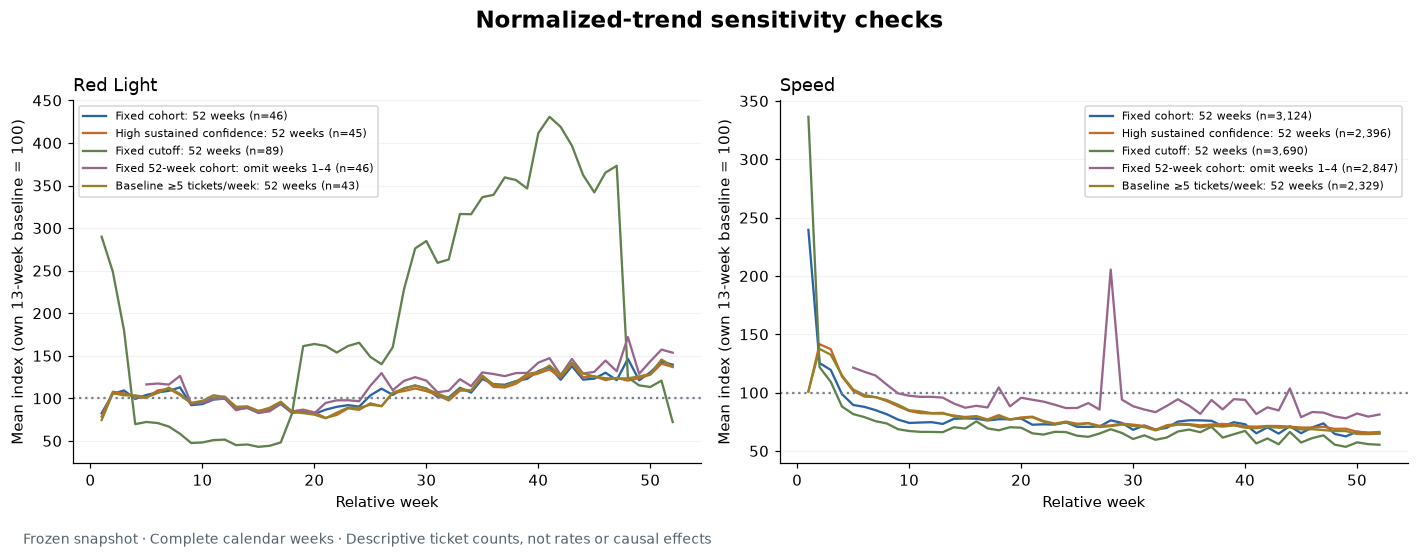

In [17]:
scenario_counts = saved_trends.loc[~saved_trends.scenario.str.startswith("cohort_")].groupby(
    ["camera_type", "scenario_label"], sort=False).agg(
        first_raw_contributors=("n", "first"), last_raw_contributors=("n", "last"),
        first_indexed_contributors=("index_n", "first"), last_relative_week=("week", "max"))
display(scenario_counts)
plot_sensitivities({"shared_trends": saved_trends}, OUT)

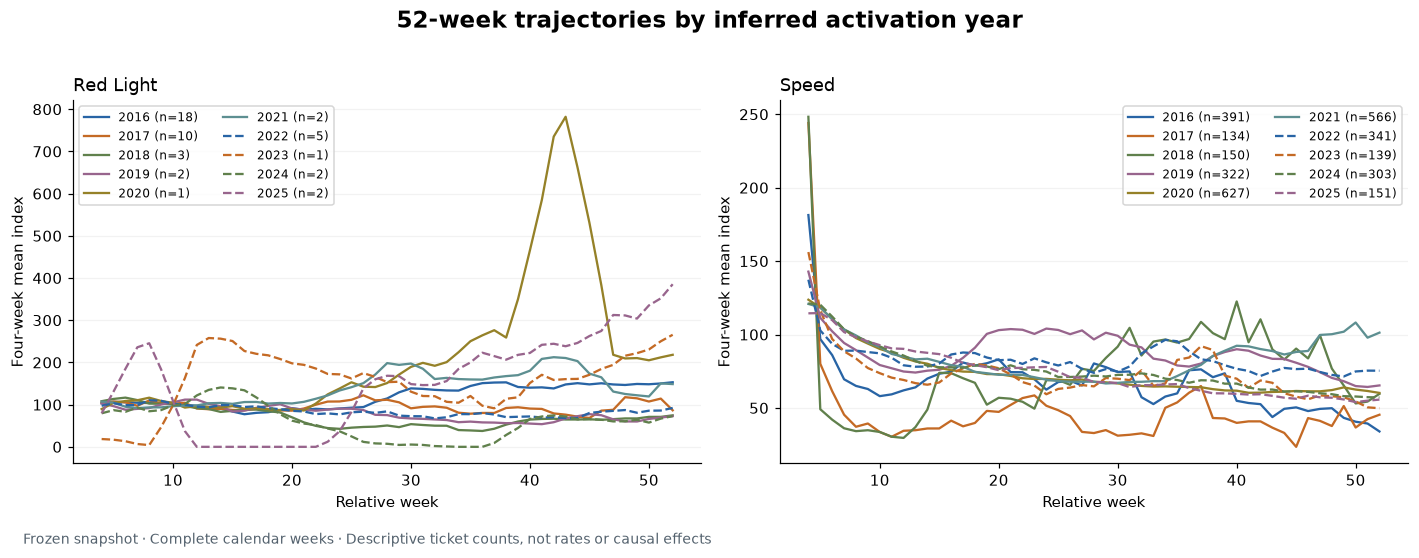

In [18]:
plot_cohorts({"shared_trends": saved_trends}, OUT)

## Checks

### 14. Reconcile the calculations to the saved tables and dashboard

Two different checks are needed: independent numerator/denominator arithmetic verifies
the calculation, while saved-table/browser comparisons verify that the same results are
displayed. Matching two exports alone would not independently validate the formula.
Tolerances allow only floating-point/JSON serialization differences.

In [19]:
numeric_columns = ["n", "raw_mean", "raw_median", "raw_q25", "raw_q75",
    "index_n", "index_mean", "index_median", "index_q25", "index_q75",
    "raw_ci_low", "raw_ci_high", "index_ci_low", "index_ci_high",
    "raw_mean_4w", "index_mean_4w", "cohort_groups"]
arithmetic_checks = pd.DataFrame([
    {"camera_type": kind, **verify_fixed_cohort_arithmetic(
        matrices[kind], indexed[kind], rebuilt[kind], len(BASELINE))}
    for kind in TYPES])
primary_checks = compare_trend_tables(
    reconstructed, saved_trends.loc[saved_trends.scenario.eq("balanced_52")],
    ["camera_type", "scenario", "week"], numeric_columns)
saved_calendar["week_start"] = pd.to_datetime(saved_calendar.week_start)
calendar_checks = compare_trend_tables(
    calendar_rebuilt, saved_calendar, ["camera_type", "scenario", "week_start"], numeric_columns)
browser = json.loads((DELIVERY / "browser/src/data.json").read_text(encoding="utf-8"))
browser_rows = pd.DataFrame(browser["queries"]["analysis_shared_trends"]["rows"])
browser_checks = compare_trend_tables(
    browser_rows, saved_trends, ["camera_type", "scenario", "week"], numeric_columns)
assert eligibility.inferred_activation_date.equals(meta.inferred_activation_date)
full_rows = weekly.loc[weekly.is_complete_week]
assert primary.sum().sum() == full_rows.observed_ticket_count.sum()
assert not reconstructed.duplicated(["camera_type", "scenario", "week"]).any()
display(arithmetic_checks)
check_summary = pd.DataFrame([
    {"Check": "Frozen input hashes", "Items checked": len(input_checks), "Passed": True},
    {"Check": "Primary camera-week arithmetic", "Items checked": arithmetic_checks.camera_weeks_checked.sum(), "Passed": True},
    {"Check": "Recomputed primary trend rows", "Items checked": len(reconstructed), "Passed": primary_checks.passed.all()},
    {"Check": "Recomputed calendar trend rows", "Items checked": len(calendar_rebuilt), "Passed": calendar_checks.passed.all()},
    {"Check": "Shared-trend browser rows", "Items checked": len(browser_rows), "Passed": browser_checks.passed.all()},
])
display(check_summary)
display(primary_checks.round(10))
reconstructed.to_csv(OUT / "recomputed_primary_trends.csv", index=False)
comparison.to_csv(OUT / "first_last_comparison.csv", index=False)
primary_checks.to_csv(OUT / "primary_reconciliation.csv", index=False)
calendar_checks.to_csv(OUT / "calendar_reconciliation.csv", index=False)
browser_checks.to_csv(OUT / "browser_reconciliation.csv", index=False)
check_summary.to_csv(OUT / "validation_summary.csv", index=False)

,camera_type,groups,weeks,camera_weeks_checked,indexed_groups,passed
0,Speed,3124,52,162448,3124,True
1,Red Light,46,52,2392,46,True


,Check,Items checked,Passed
0,Frozen input hashes,4,True
1,Primary camera-week arithmetic,164840,True
2,Recomputed primary trend rows,104,True
3,Recomputed calendar trend rows,1058,True
4,Shared-trend browser rows,2875,True


,field,rows_checked,maximum_absolute_difference,passed
0,n,104,0.0,True
1,raw_mean,104,0.0,True
2,raw_median,104,0.0,True
3,raw_q25,104,0.0,True
4,raw_q75,104,0.0,True
5,index_n,104,0.0,True
6,index_mean,104,0.0,True
7,index_median,104,0.0,True
8,index_q25,104,0.0,True
9,index_q75,104,0.0,True


## Next Steps

The speed cohort's raw mean falls from about **84.4 to 52.4 tickets per group per week**.
The red-light cohort's mean rises from about **56.0 to 61.1**. These statements compare
the first and last 13 weeks of the same 52-week cohort, not all historical cameras.
Only **46 of 617 red-light groups** meet the primary requirement.

Read mean, median, individual examples, contributing counts, and sensitivity curves together.
The first observed activity is not verified installation, and the final ticket is not verified
deactivation. Ticket counts also depend on traffic exposure, enforcement hours, processing,
and other factors not identified by this descriptive analysis.

For the next stage, [Shared Ticket Trends and Clusters](Shared_Ticket_Trends_and_Clusters.html)
explains the separate shape-clustering analysis. Its input is the same complete 52-week
matrix, followed by four-week block means, log1p and within-group standardization.
That transformation is different from the baseline-100 index taught here.

Rebuild this walkthrough from the repository root with:

    uv run python experiments/camera-ticket-trends/build_trend_walkthrough.py

This produces an executed notebook, an HTML reading copy, PNG figures, arithmetic tables,
validation results and file hashes. Existing analytical results and the dashboard remain unchanged.